# Day 8: Bernoulli, Binomial and Poisson Distributions

## Learning Objectives

By the end of this notebook, you will be able to:

- Understand discrete probability distributions.
- Understand the Bernoulli distribution.
- Understand the Binomial distribution.
- Understand the Poisson distribution.
- Calculate probabilities using SciPy.
- Calculate expected values and variances.
- Differentiate between Bernoulli, Binomial and Poisson distributions.
- Apply these distributions to business problems.

## 1. Introduction to Discrete Probability Distributions

A probability distribution describes the possible values of a random variable
and the probability associated with each value.

A discrete probability distribution is used when a random variable
takes countable values.

Examples:

- Number of customers making a purchase.
- Number of defective products.
- Number of complaints received.
- Number of successful loan applications.

Today we will study three important discrete distributions:

1. Bernoulli Distribution
2. Binomial Distribution
3. Poisson Distribution

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import bernoulli, binom, poisson

## 2. Bernoulli Distribution

A Bernoulli distribution represents a random experiment
with only two possible outcomes.

- Success = 1
- Failure = 0

Examples:

- Customer purchases or does not purchase.
- Loan application is approved or rejected.
- Product is defective or non-defective.
- Email is opened or not opened.

Let:

p = Probability of success

1 - p = Probability of failure

### Probability Formula

P(X = x) = p^x × (1 - p)^(1-x)

Where:

X can take only 0 or 1.

### Mean

E(X) = p

### Variance

Var(X) = p × (1 - p)

In [ ]:
# Bernoulli distribution example

# Probability of a customer making a purchase
p = 0.70

# Calculate probabilities
probability_failure = bernoulli.pmf(0, p)
probability_success = bernoulli.pmf(1, p)

print("Probability of Failure:", probability_failure)
print("Probability of Success:", probability_success)

print("Mean:", bernoulli.mean(p))
print("Variance:", bernoulli.var(p))

In [2]:
# Simulate customer purchase outcomes

np.random.seed(42)

purchase_outcomes = bernoulli.rvs(
    p=0.70,
    size=100
)

print("First 20 Outcomes:")
print(purchase_outcomes[:20])

print("Total Customers:", len(purchase_outcomes))
print("Successful Purchases:", purchase_outcomes.sum())
print("Observed Purchase Rate:", purchase_outcomes.mean())

First 20 Outcomes:
[1 0 0 1 1 1 1 0 1 0 1 0 0 1 1 1 1 1 1 1]
Total Customers: 100
Successful Purchases: 70
Observed Purchase Rate: 0.7


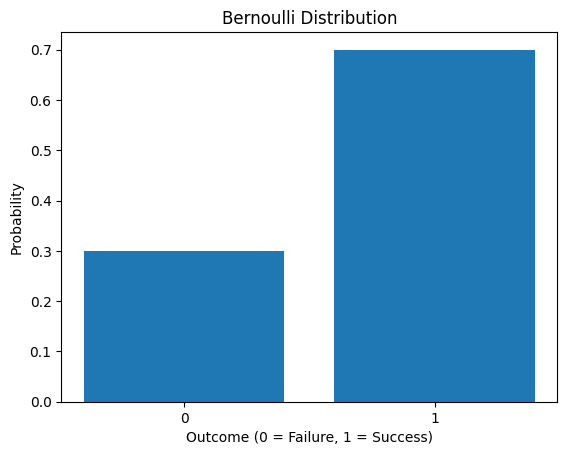

In [3]:
# Visualize Bernoulli distribution

outcomes = [0, 1]

probabilities = bernoulli.pmf(
    outcomes,
    p=0.70
)

plt.bar(outcomes, probabilities)

plt.title("Bernoulli Distribution")
plt.xlabel("Outcome (0 = Failure, 1 = Success)")
plt.ylabel("Probability")
plt.xticks([0, 1])

plt.show()

## 3. Binomial Distribution

The Binomial distribution calculates the probability
of obtaining a specific number of successes
in a fixed number of independent trials.

### Conditions

1. Fixed number of trials (n).
2. Each trial has two possible outcomes.
3. Trials are independent.
4. Probability of success (p) remains constant.

Examples:

- Number of customers purchasing among 20 visitors.
- Number of successful loan applications among 50 applications.
- Number of defective products in a sample of 100 items.

### Probability Formula

P(X = k) = C(n, k) × p^k × (1-p)^(n-k)

Where:

- n = Total number of trials.
- k = Number of successes.
- p = Probability of success.
- C(n, k) = Number of combinations.

### Mean

E(X) = n × p

### Variance

Var(X) = n × p × (1-p)

In [ ]:
# Binomial distribution example

# Number of customers
n = 20

# Probability of purchase
p = 0.30

# Probability of exactly 5 customers purchasing
probability_exactly_5 = binom.pmf(
    5,
    n,
    p
)

print(
    "Probability of Exactly 5 Purchases:",
    round(probability_exactly_5, 4)
)

print("Mean:", binom.mean(n, p))
print("Variance:", binom.var(n, p))

In [4]:
# Calculate different Binomial probabilities

n = 20
p = 0.30

probability_0 = binom.pmf(0, n, p)
probability_5 = binom.pmf(5, n, p)
probability_10 = binom.pmf(10, n, p)

print("P(X = 0):", round(probability_0, 4))
print("P(X = 5):", round(probability_5, 4))
print("P(X = 10):", round(probability_10, 4))

P(X = 0): 0.0008
P(X = 5): 0.1789
P(X = 10): 0.0308


In [5]:
# Calculate cumulative Binomial probability

# Probability of 5 or fewer successful purchases

probability_at_most_5 = binom.cdf(
    5,
    n,
    p
)

# Probability of more than 5 successful purchases

probability_more_than_5 = 1 - binom.cdf(
    5,
    n,
    p
)

print(
    "P(X <= 5):",
    round(probability_at_most_5, 4)
)

print(
    "P(X > 5):",
    round(probability_more_than_5, 4)
)

P(X <= 5): 0.4164
P(X > 5): 0.5836


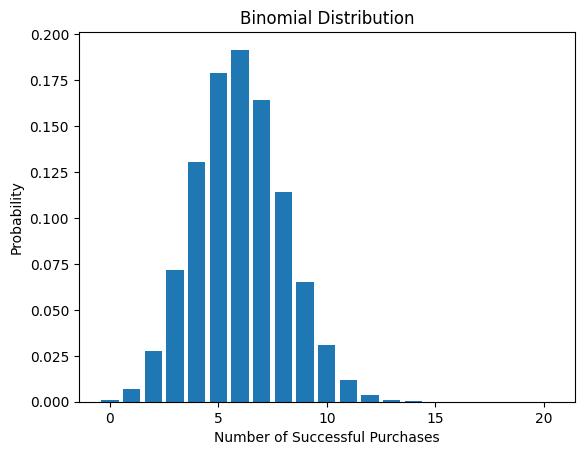

In [6]:
# Visualize Binomial distribution

x = np.arange(0, n + 1)

probabilities = binom.pmf(
    x,
    n,
    p
)

plt.bar(x, probabilities)

plt.title("Binomial Distribution")
plt.xlabel("Number of Successful Purchases")
plt.ylabel("Probability")

plt.show()

## 4. Poisson Distribution

The Poisson distribution calculates the probability
of a specific number of events occurring
within a fixed interval of time or space.

It is commonly used when events occur independently
at a relatively stable average rate.

Examples:

- Number of customer complaints per hour.
- Number of website visitors per minute.
- Number of delivery delays per day.
- Number of machine failures per month.

### Conditions and Assumptions

- Events occur independently.
- The average event rate is constant over the interval.
- Events occur individually rather than in clusters
  at exactly the same instant.

### Probability Formula

P(X = k) = (e^(-λ) × λ^k) / k!

Where:

- λ (lambda) = Average number of events in the interval.
- k = Number of events.
- e = Euler's number.

### Mean

E(X) = λ

### Variance

Var(X) = λ

Important:

For a Poisson distribution, mean and variance are equal.

In [7]:
# Poisson distribution example

# Average number of customer complaints per hour
lambda_rate = 4

# Probability of exactly 3 complaints
probability_exactly_3 = poisson.pmf(
    3,
    lambda_rate
)

print(
    "Probability of Exactly 3 Complaints:",
    round(probability_exactly_3, 4)
)

print("Mean:", poisson.mean(lambda_rate))
print("Variance:", poisson.var(lambda_rate))

Probability of Exactly 3 Complaints: 0.1954
Mean: 4.0
Variance: 4.0


In [8]:
# Calculate different Poisson probabilities

lambda_rate = 4

probability_0 = poisson.pmf(0, lambda_rate)
probability_3 = poisson.pmf(3, lambda_rate)
probability_6 = poisson.pmf(6, lambda_rate)

print("P(X = 0):", round(probability_0, 4))
print("P(X = 3):", round(probability_3, 4))
print("P(X = 6):", round(probability_6, 4))

P(X = 0): 0.0183
P(X = 3): 0.1954
P(X = 6): 0.1042


In [9]:
# Calculate cumulative Poisson probability

# Probability of 3 or fewer complaints

probability_at_most_3 = poisson.cdf(
    3,
    lambda_rate
)

# Probability of more than 3 complaints

probability_more_than_3 = 1 - poisson.cdf(
    3,
    lambda_rate
)

print(
    "P(X <= 3):",
    round(probability_at_most_3, 4)
)

print(
    "P(X > 3):",
    round(probability_more_than_3, 4)
)

P(X <= 3): 0.4335
P(X > 3): 0.5665


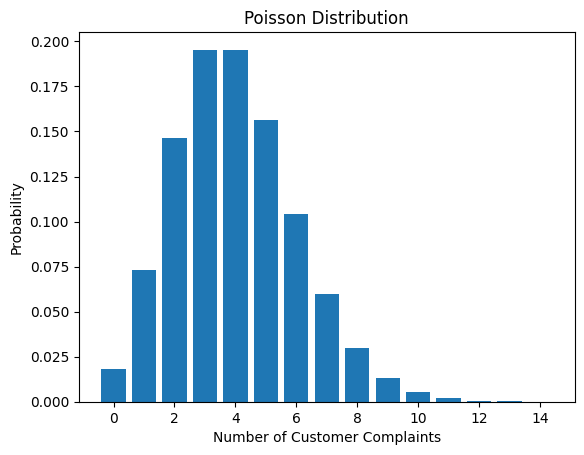

In [10]:
# Visualize Poisson distribution

x = np.arange(0, 15)

probabilities = poisson.pmf(
    x,
    lambda_rate
)

plt.bar(x, probabilities)

plt.title("Poisson Distribution")
plt.xlabel("Number of Customer Complaints")
plt.ylabel("Probability")

plt.show()

## 5. Comparison of Bernoulli, Binomial and Poisson Distributions

| Feature | Bernoulli | Binomial | Poisson |
|---|---|---|---|
| Purpose | One binary trial | Number of successes in fixed trials | Number of events in an interval |
| Outcomes | 0 or 1 | 0 to n | 0, 1, 2, 3, ... |
| Parameters | p | n, p | λ |
| Mean | p | np | λ |
| Variance | p(1-p) | np(1-p) | λ |
| Example | One customer purchases | Purchases among 20 customers | Complaints per hour |

### Key Difference

- Bernoulli: One trial.
- Binomial: Fixed number of independent Bernoulli trials.
- Poisson: Number of events in a fixed interval, given an average rate.

## 6. Relationship Between Bernoulli, Binomial and Poisson

### Bernoulli and Binomial

A Binomial distribution can be understood as the sum
of multiple independent Bernoulli trials
with the same probability of success.

For example:

If 10 customers independently decide whether to purchase,
each customer's purchase outcome can be modeled using Bernoulli.

The total number of purchases can be modeled using Binomial.

### Binomial and Poisson Approximation

A Binomial distribution can sometimes be approximated
by a Poisson distribution when:

- n is sufficiently large.
- p is small.
- λ = n × p remains finite.

A common rule of thumb is to consider this approximation
when n is large and p is relatively small.

It is an approximation, not an exact identity.

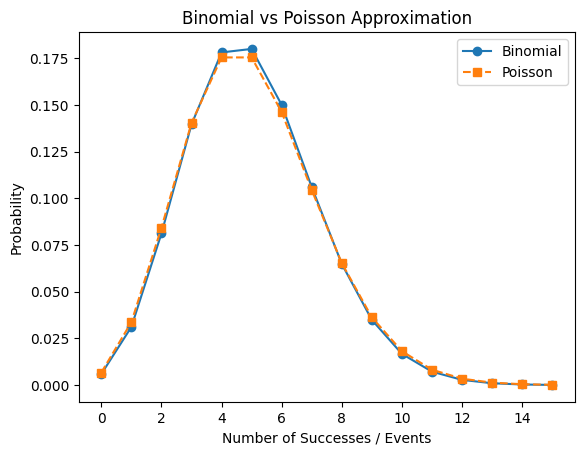

In [11]:
# Compare Binomial and Poisson probabilities

n = 100
p = 0.05

lambda_rate = n * p

x = np.arange(0, 16)

binomial_probabilities = binom.pmf(
    x,
    n,
    p
)

poisson_probabilities = poisson.pmf(
    x,
    lambda_rate
)

plt.plot(
    x,
    binomial_probabilities,
    marker="o",
    label="Binomial"
)

plt.plot(
    x,
    poisson_probabilities,
    marker="s",
    linestyle="--",
    label="Poisson"
)

plt.title("Binomial vs Poisson Approximation")
plt.xlabel("Number of Successes / Events")
plt.ylabel("Probability")

plt.legend()
plt.show()

## 7. Practical Business Applications

### E-commerce

- Bernoulli: Whether a customer purchases a product.
- Binomial: Number of purchases among a fixed group of visitors.
- Poisson: Number of orders received within an hour.

### Banking

- Bernoulli: Whether a loan application defaults or does not default.
- Binomial: Number of successful applications in a fixed sample.
- Poisson: Number of fraud alerts within a given time interval,
  when the assumptions are reasonable.

### Manufacturing

- Bernoulli: Whether a product is defective.
- Binomial: Number of defective products in a sample.
- Poisson: Number of defects occurring over a fixed length
  or production interval, when the assumptions are reasonable.

### Operations

- Bernoulli: Whether a delivery is delayed.
- Binomial: Number of delayed deliveries among a fixed number of orders.
- Poisson: Number of customer complaints received per hour.

## 8. Important Functions in SciPy

| Function | Purpose |
|---|---|
| pmf() | Probability Mass Function: exact probability |
| cdf() | Cumulative Distribution Function: probability up to a value |
| rvs() | Generate random samples |
| mean() | Calculate theoretical mean |
| var() | Calculate theoretical variance |

Examples:

- binom.pmf(5, 20, 0.30)
- binom.cdf(5, 20, 0.30)
- poisson.pmf(3, 4)
- poisson.cdf(3, 4)
- bernoulli.rvs(0.70, size=100)

Remember:

For discrete distributions, PMF gives the probability of an exact value,
whereas CDF gives the probability of that value or anything below it.

## 9. Interview Questions and Answers

### Q1. What is a Bernoulli distribution?

It models a single experiment with two possible outcomes:
success or failure.

### Q2. What is a Binomial distribution?

It models the number of successes in a fixed number
of independent trials with a constant probability of success.

### Q3. What is a Poisson distribution?

It models the number of events occurring within a fixed interval
when events occur independently at a constant average rate.

### Q4. What is the difference between Bernoulli and Binomial?

Bernoulli models one trial, whereas Binomial models
the number of successes across multiple trials.

### Q5. What is the difference between Binomial and Poisson?

Binomial uses a fixed number of trials and a probability of success.
Poisson uses an average event rate over a fixed interval.

### Q6. What are the mean and variance of a Binomial distribution?

Mean = np

Variance = np(1-p)

### Q7. What is special about the Poisson distribution?

Its mean and variance are both equal to lambda (λ).

### Q8. What is PMF?

PMF gives the probability that a discrete random variable
takes one exact value.

### Q9. What is CDF?

CDF gives the probability that a random variable
is less than or equal to a specified value.

### Q10. When can Poisson approximate Binomial?

When the number of trials is sufficiently large,
the probability of success is small,
and np remains finite.

## 10. Practice Tasks

Try solving these independently using Python and SciPy.

### Task 1: Bernoulli Distribution

A customer has a 65% probability of purchasing a product.

Calculate:

1. Probability of purchase.
2. Probability of no purchase.
3. Expected value.
4. Variance.

### Task 2: Binomial Distribution

An e-commerce website has 15 visitors.
Each visitor has a 20% probability of making a purchase.

Calculate:

1. Probability of exactly 4 purchases.
2. Probability of at most 4 purchases.
3. Probability of more than 4 purchases.
4. Expected number of purchases.
5. Variance.

### Task 3: Poisson Distribution

A customer support team receives an average of 5 complaints per hour.

Calculate:

1. Probability of exactly 3 complaints.
2. Probability of no complaints.
3. Probability of at most 3 complaints.
4. Probability of more than 3 complaints.
5. Expected number of complaints.
6. Variance.

### Task 4: Distribution Selection

Identify the most suitable distribution:

1. Whether one customer purchases a product.
2. Number of successful purchases among 30 independent visitors.
3. Number of calls received by a support center per hour.

### Task 5: Business Application

A manufacturing company checks 100 products.
Each product independently has a 3% probability of being defective.

Calculate the probability of exactly 2 defective products.

Also calculate the expected number of defective products.

## 11. Key Takeaways

- Bernoulli models a single binary trial.
- Binomial models successes across a fixed number of independent trials.
- Poisson models event counts over a fixed interval.
- PMF calculates exact probabilities.
- CDF calculates cumulative probabilities.
- Bernoulli, Binomial and Poisson distributions have different assumptions.
- Poisson can approximate Binomial under suitable conditions.
- These distributions are useful in business analytics and risk analysis.

## Next Topic

Day 9: Normal Distribution, Sampling and Sampling Techniques.